In [148]:
# Ethan Johnson
# Assigment 3

"""
Created By    : Jared W. Marquis
Creation Date : 01 August 2022
Course        : ATSC 528 - Atmospheric Data Analysis
Assignment    : #02 - Successive Corrections

Purpose:
Script to take sparse upper air observations and analyze them on a
polar stereographic map projection using successive corrections.
[PUT MORE INFORMATION HERE - I.E., WHAT SPECIFIC THING IS BEING DONE]

"""
__author__    = "Jared W. Marquis"
__contact__   = "jared.marquis@und.edu"

In [149]:
### Import Required Modules (shouldn't need to change) ###
import numpy as np                 #numpy for math
import matplotlib.pyplot as plt    #matplotlib for plotting
import cartopy.crs as ccrs         #cartopy for plotting on map
import cartopy.feature as cfeature #cartopy basic shapefiles
import pandas as pd

In [150]:
### Create function for Cressman Analysis ###

def cressman(d, roi): ## weight function
    w = np.where(d<=roi, (roi**2 - d**2) / (roi**2 + d**2), 0.0)
    return w

def cressman_analysis(ax, ay, ox, oy, val, roi):
    d = np.sqrt((ox-ax)**2+(oy-ay)**2)
    w = cressman(d, roi)
    sum_w = w.sum()
    if sum_w == 0:
        return np.nan
    return (w * val).sum() / sum_w

In [151]:
### Create function for bilinear interpolation ###

def bilinear(grid, fi, fj, NX, NY):
    if np.isnan(fi) or np.isnan(fj):
        return np.isnan
    i_l = np.floor(fi).astype(int) # floor and ceiling stuff we did in class
    i_u = np.ceil(fi).astype(int)
    j_l = np.floor(fj).astype(int)
    j_u = np.ceil(fj).astype(int)

    if i_l < 0 or j_l < 0 or i_u > NX - 1 or j_u > NY - 1:
        return np.nan

    di = fi - i_l
    dj = fj - j_l
    val = ((1-di)*(1-dj)*grid[i_l,j_l] + di*(1-dj)*grid[i_u,j_l] + (1-di)*dj*grid[i_l,j_u] + di*dj*grid[i_u,j_u]) # bilinear interpolation formula
    return val

In [152]:
### Read in observations ###
df = pd.read_csv('RAOBs_201903131200.txt', header=None, names=['station','lat','lon','z_500','udir','uspd'])

In [153]:
### Set up analysis map with a 21x27 rectangular grid of points ###
rho = 6371.0                   # km
phi0 = np.radians(60.0)        # standard latitude
lam0 = -100.0                  # reference longitude,
m = 1 / 15_000_000             # map scale

SCALE_TOP = 1 + np.sin(phi0)  


def r_from_pole_km(lat_deg):
    phi = np.radians(lat_deg)
    return rho * np.cos(phi) * SCALE_TOP / (1 + np.sin(phi))


def latlon_to_xy_cm(lat_deg, lon_deg):
    r_km = r_from_pole_km(lat_deg)
    r_map_cm = r_km * m * 100_000
    dlam = np.radians(lon_deg - lam0)
    x = r_map_cm * np.cos(dlam)
    y = r_map_cm * np.sin(dlam)
    return x, y


def xy_cm_to_latlon(x_cm, y_cm):
    r_map_cm = np.hypot(x_cm, y_cm)
    r_km = (r_map_cm / 100_000) / m
    ratio = r_km / (rho * SCALE_TOP)
    phi = np.pi / 2 - 2 * np.arctan(ratio)
    lat_deg = np.degrees(phi)
    dlam = np.arctan2(y_cm, x_cm)
    lon_deg = (lam0 + np.degrees(dlam) + 180) % 360 - 180
    return lat_deg, lon_deg


# 21 x 27 grid setup
NX, NY = 21, 27
DX = DY = 1.27                 
X0, Y0 = 25.0, -15.5           

x_vals = X0 + np.arange(NX) * DX
y_vals = Y0 + np.arange(NY) * DY

gyy, gxx = np.meshgrid(y_vals, x_vals)

grid_lat = np.empty((NX, NY))
grid_lon = np.empty((NX, NY))
for i, x in enumerate(x_vals):
    for j, y in enumerate(y_vals):
        lat, lon = xy_cm_to_latlon(x, y)
        grid_lat[i, j] = lat
        grid_lon[i, j] = lon


In [154]:
### convert obs lat/long to x,y ###
obs_x, obs_y = latlon_to_xy_cm(df["lat"].values, df["lon"].values)
obs_z = df['z_500'].values
n_obs = len(obs_x)

df['x_cm'], df['y_cm'] = latlon_to_xy_cm(df['lat'].values, df['lon'].values)
x_cm, y_cm = np.meshgrid(x_vals, y_vals, indexing='ij')

In [155]:
### Perform 500mb geopotential height analyses using a Cressman weighting Function###
#Use radii of influence 4, 2.5, 1.5 *dmin

nearest = np.zeros(n_obs)
for k in range(n_obs):
    dist = np.sqrt((obs_x-obs_x[k])**2 + (obs_y-obs_y[k])**2)
    dist[k] = np.inf 
    nearest[k] = dist.min() 
dmin = nearest.mean()

roi1 = 4.0 * dmin
roi2 = 2.5 * dmin
roi3 = 1.5 * dmin

In [156]:
### First analysis, no successive corrections ###
pass1 = np.full((NX, NY), np.nan)
n_obs1 = np.zeros((NX, NY), dtype=int)       # number of obs used at each grid point

for i in range(NX):
    for j in range(NY):
        pass1[i, j] = cressman_analysis(x_cm[i, j], y_cm[i, j], obs_x, obs_y, obs_z, roi1)
        d = np.hypot(obs_x - x_cm[i, j], obs_y - y_cm[i, j])
        n_obs1[i, j] = (d <= roi1).sum()

In [157]:
### Next Analyses ###

# fractional grid indices to be used for binilear interpolation later
df['i'] = (df['x_cm'] - X0) / DX 
df['j'] = (df['y_cm'] - Y0) / DY

#Pass 1 analysis at each observation location
fi_all, fj_all = df['i'].values, df['j'].values
ok = np.isfinite(pass1.ravel())
Xg, Yg, Fg = x_cm.ravel()[ok], y_cm.ravel()[ok], pass1.ravel()[ok]
pass1_obs = np.full(n_obs, np.nan)
for k in range(n_obs):
    b = bilinear(pass1, fi_all[k], fj_all[k], NX, NY)   # bilinear inside the grid
    if np.isnan(b):                                     # outside the grid >> NaN
        b = cressman_analysis(obs_x[k], obs_y[k], Xg, Yg, Fg, roi1)
    pass1_obs[k] = b

# pass 2
pass2 = np.full((NX, NY), np.nan)
ok = np.isfinite(pass1_obs) # stations with a valid analysis value
for i in range(NX):
    for j in range(NY):
        if np.isnan(pass1[i, j]):
            continue
        d = np.sqrt((obs_x[ok] - x_cm[i, j])**2 + (obs_y[ok] - y_cm[i, j])**2)
        w = cressman(d, roi2)
        sum_w = w.sum()
        if sum_w == 0:
            pass2[i, j] = pass1[i, j] # no close obs, no correction
            continue
        correction = (w * (obs_z[ok] - pass1_obs[ok])).sum() / sum_w
        pass2[i, j] = pass1[i, j] + correction
pass2_obs = np.full(n_obs, np.nan)
for k in range(n_obs):
    b = bilinear(pass2, fi_all[k], fj_all[k], NX, NY)
    if np.isnan(b):
        b = cressman_analysis(obs_x[k], obs_y[k], Xg, Yg, pass2.ravel(), roi2)
    pass2_obs[k]=b

# pass 3
pass3 = np.full((NX, NY), np.nan)
ok = np.isfinite(pass2_obs) 
for i in range(NX):
    for j in range(NY):
        if np.isnan(pass2[i, j]):
            continue
        d = np.sqrt((obs_x[ok] - x_cm[i, j])**2 + (obs_y[ok] - y_cm[i, j])**2) 
        w = cressman(d, roi3)
        sum_w = w.sum()
        if sum_w == 0:
            pass3[i, j] = pass2[i, j]
            continue
        correction = (w * (obs_z[ok] - pass2_obs[ok])).sum() / sum_w
        pass3[i, j] = pass2[i, j] + correction
pass3_obs = np.full(n_obs, np.nan)
for k in range(n_obs):
    b = bilinear(pass3, fi_all[k], fj_all[k], NX, NY)
    if np.isnan(b):
        b = cressman_analysis(obs_x[k], obs_y[k], Xg, Yg, pass3.ravel(), roi3)
    pass3_obs[k] = b

In [158]:
### Calculate Analysis Differences

diff21 = pass2 - pass1
diff32 = pass3 - pass2
diff31 = pass3 - pass1

print('2-1:', np.nanmin(diff21), np.nanmax(diff21))
print('3-1:', np.nanmin(diff32), np.nanmax(diff32))
print('3-2:', np.nanmin(diff31), np.nanmax(diff31))

k1 = np.sum(np.isfinite(pass1_obs)) # number of obs used in pass 1
k2 = np.sum(np.isfinite(pass2_obs)) # " " " " " pass 2
k3 = np.sum(np.isfinite(pass3_obs)) # " " " " " pass 3

rmse1 = np.sqrt(np.nansum((obs_z - pass1_obs)**2) / k1)
rmse2 = np.sqrt(np.nansum((obs_z - pass2_obs)**2) / k2)
rmse3 = np.sqrt(np.nansum((obs_z - pass3_obs)**2) / k3)

print(k1, rmse1)
print(k2, rmse2)
print(k3, rmse3)

2-1: -129.64902009856633 154.02998500741705
3-1: -58.81123372678758 43.720868658019754
3-2: -171.9193699275629 195.17865267327397
114 85.35084349383479
108 37.95754682302207
101 11.569333186758767


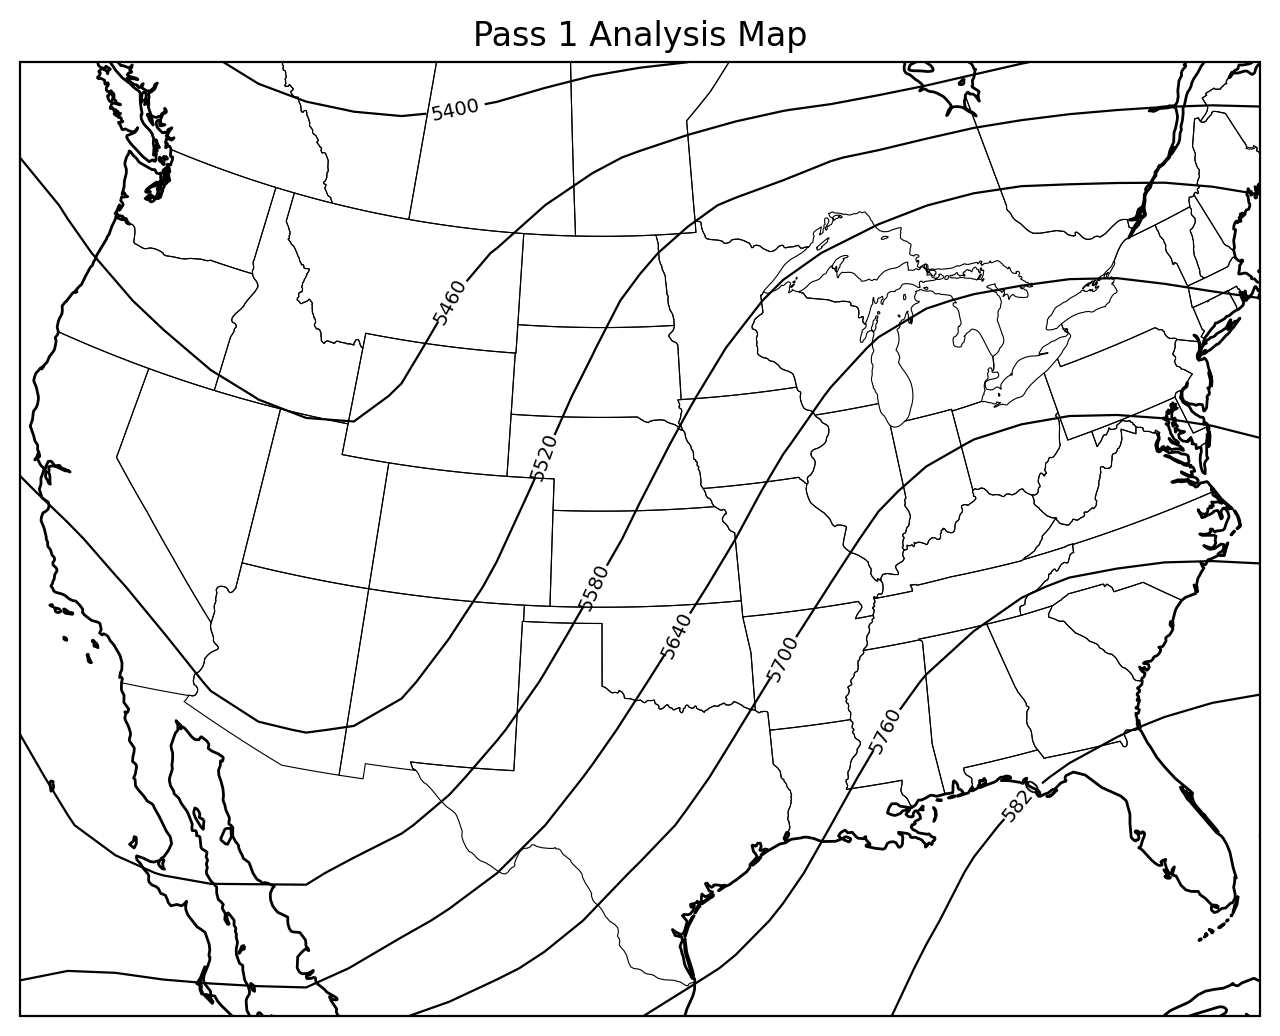

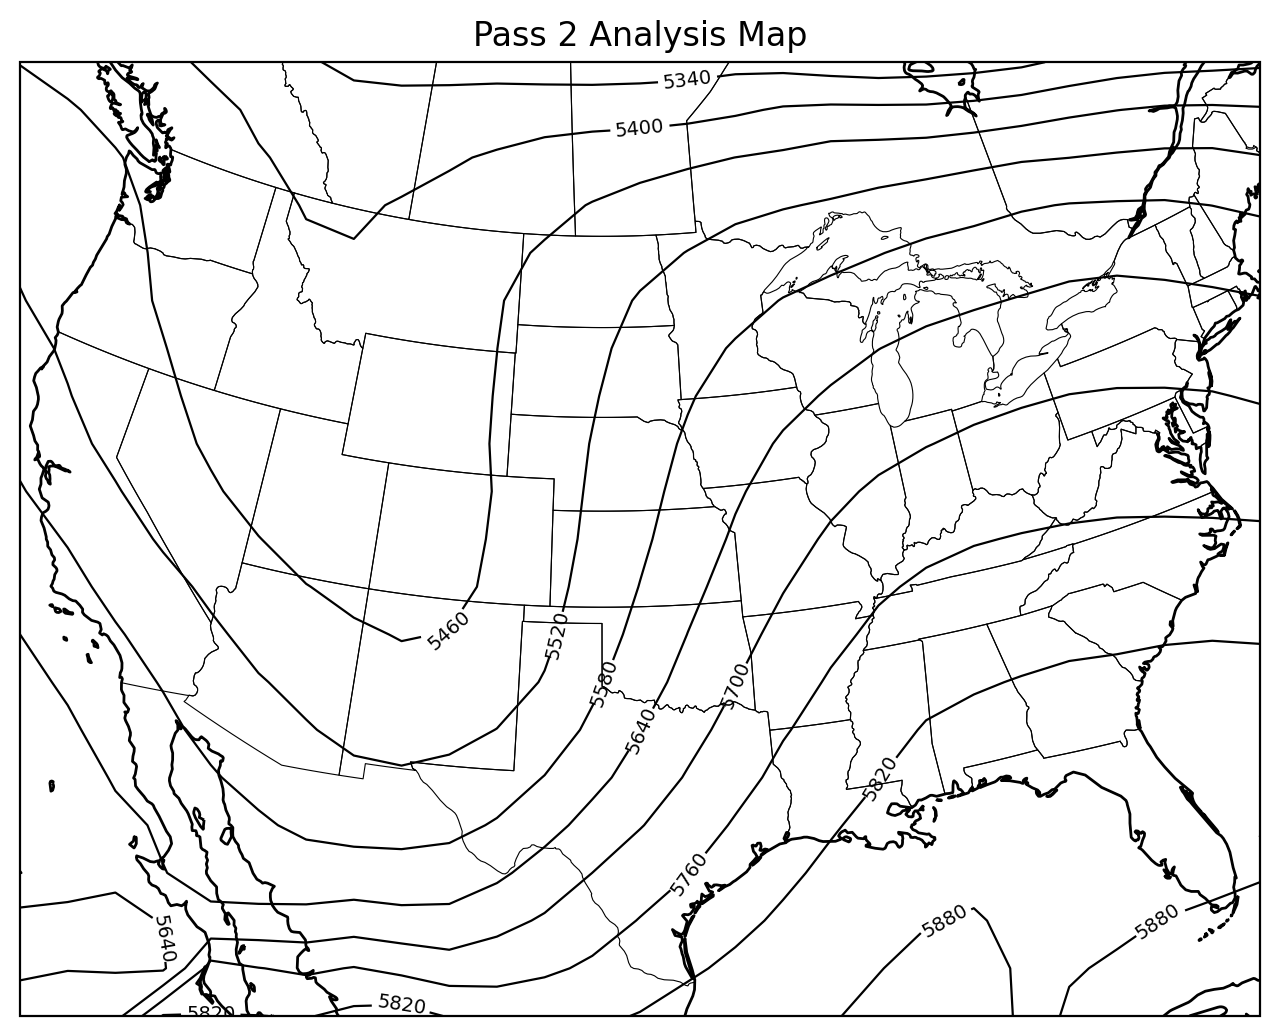

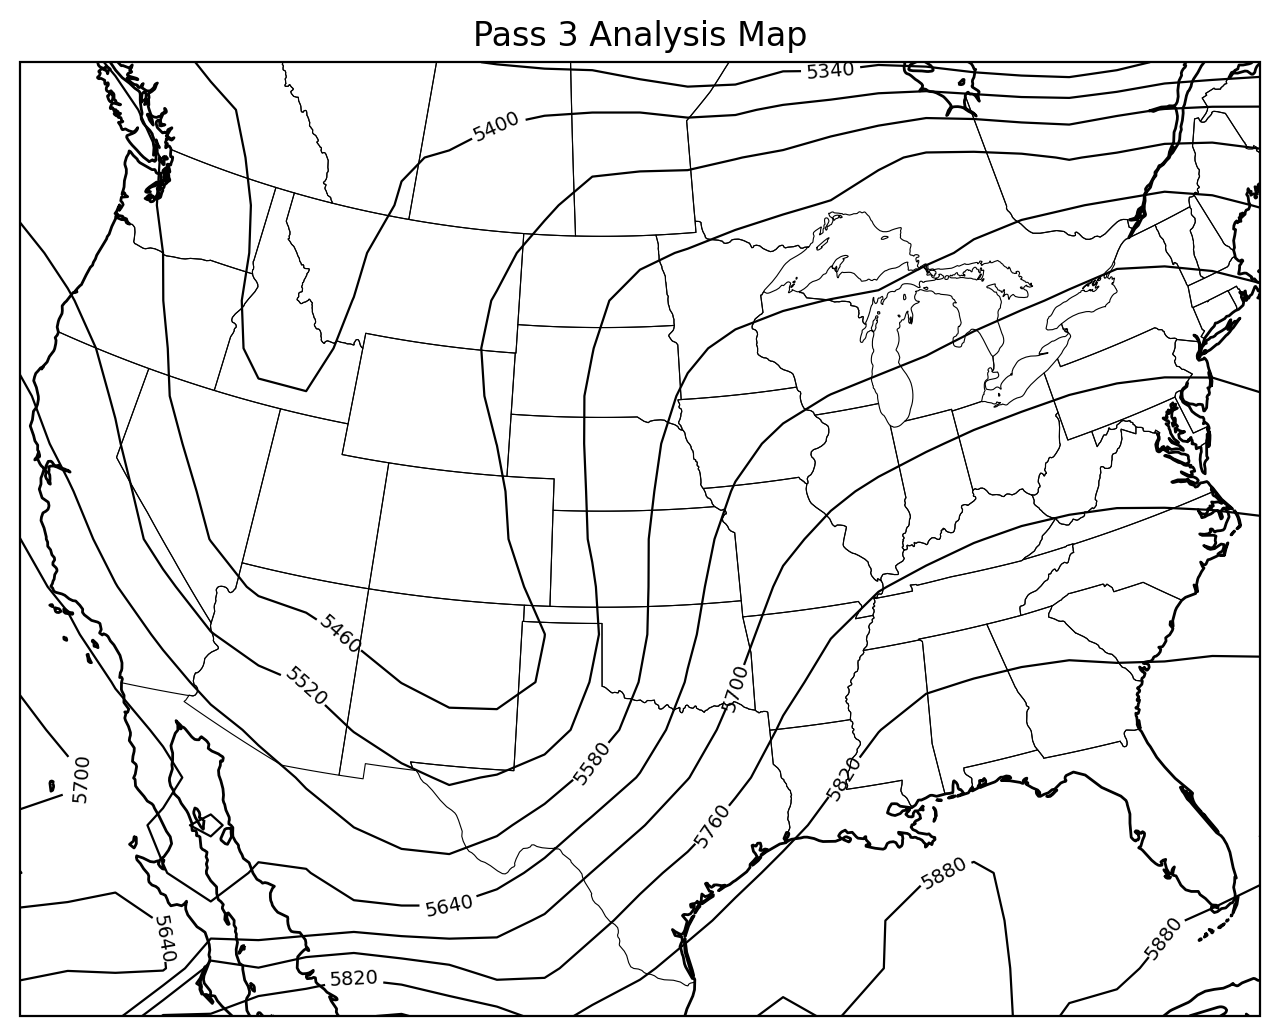

In [161]:
### Plot 500mb analyses over a map ###
#use old code...

globe = ccrs.Globe(ellipse=None, semimajor_axis=rho*1000, semiminor_axis=rho*1000)
proj = ccrs.Stereographic(central_longitude=lam0,central_latitude=90,true_scale_latitude=60.0,globe=globe)

map_x = y_cm / 100 / m
map_y = -x_cm / 100 / m

hgt_levels = np.arange(4800, 6000, 60) 

# pass 1
fig = plt.figure(figsize=(8, 8), dpi=200)
ax1 = fig.add_subplot(111, projection=proj)
ax1.add_feature(cfeature.STATES, linewidth=0.4)
ax1.add_feature(cfeature.COASTLINE)
cs1 = ax1.contour(map_x, map_y, pass1, levels=hgt_levels, colors='k', linewidths=0.8, transform=proj)
ax1.clabel(cs1, fmt='%d', fontsize=7)
ax1.set_extent([map_x.min(), map_x.max(), map_y.min(), map_y.max()], crs=proj)
ax1.set_title('Pass 1 Analysis Map')
#plt.savefig('pass1_map.png', dpi=300, bbox_inches='tight')
plt.show()

# pass 2
fig = plt.figure(figsize=(8, 8), dpi=200)
ax2 = fig.add_subplot(111, projection=proj)
ax2.add_feature(cfeature.STATES, linewidth=0.4)
ax2.add_feature(cfeature.COASTLINE)
cs2 = ax2.contour(map_x, map_y, pass2, levels=hgt_levels, colors='k', linewidths=0.8, transform=proj)
ax2.clabel(cs2, fmt='%d', fontsize=7)
ax2.set_extent([map_x.min(), map_x.max(), map_y.min(), map_y.max()], crs=proj)
ax2.set_title('Pass 2 Analysis Map')
#plt.savefig('pass2_map.png', dpi=300, bbox_inches='tight')
plt.show()

# pass 3
fig = plt.figure(figsize=(8, 8), dpi=200)
ax3 = fig.add_subplot(111, projection=proj)
ax3.add_feature(cfeature.STATES, linewidth=0.4)
ax3.add_feature(cfeature.COASTLINE)
cs3 = ax3.contour(map_x, map_y, pass3, levels=hgt_levels, colors='k', linewidths=0.8, transform=proj)
ax3.clabel(cs3, fmt='%d', fontsize=7)
ax3.set_extent([map_x.min(), map_x.max(), map_y.min(), map_y.max()], crs=proj)
ax3.set_title('Pass 3 Analysis Map')
plt.savefig('pass3_map.png', dpi=300, bbox_inches='tight')
plt.show()


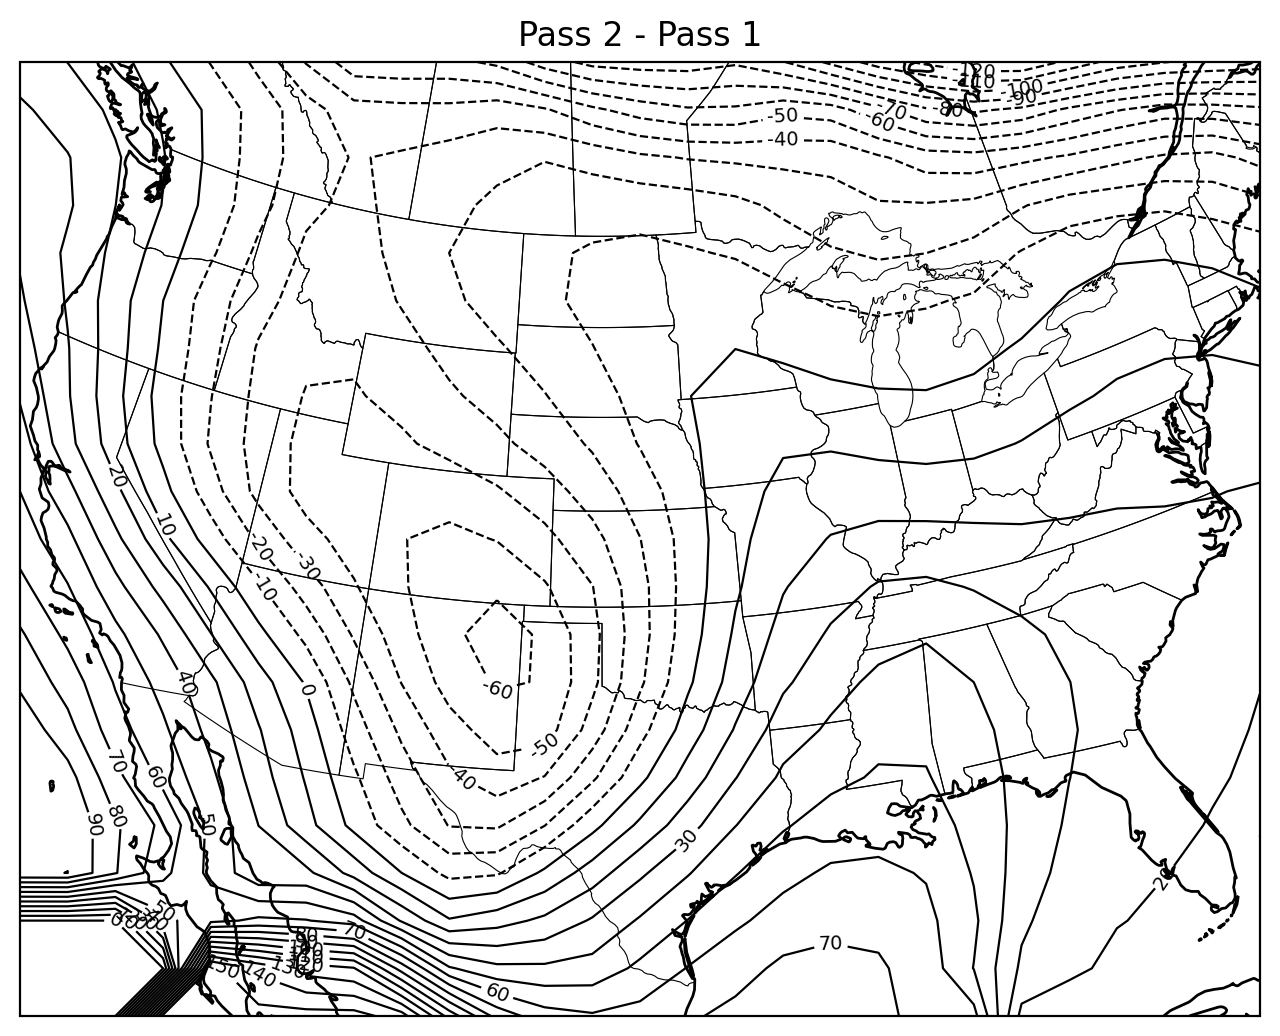

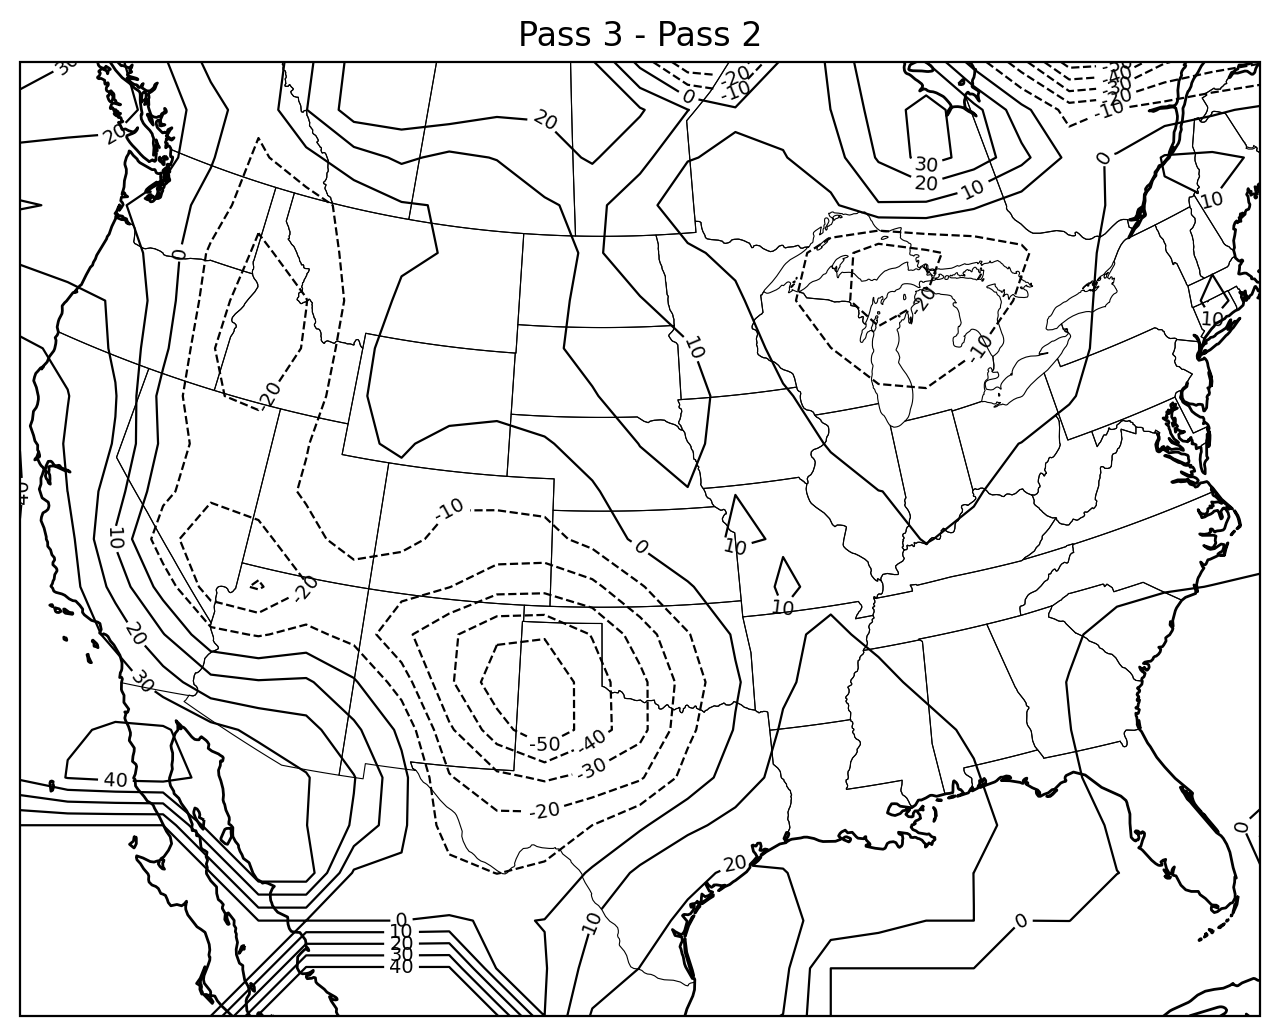

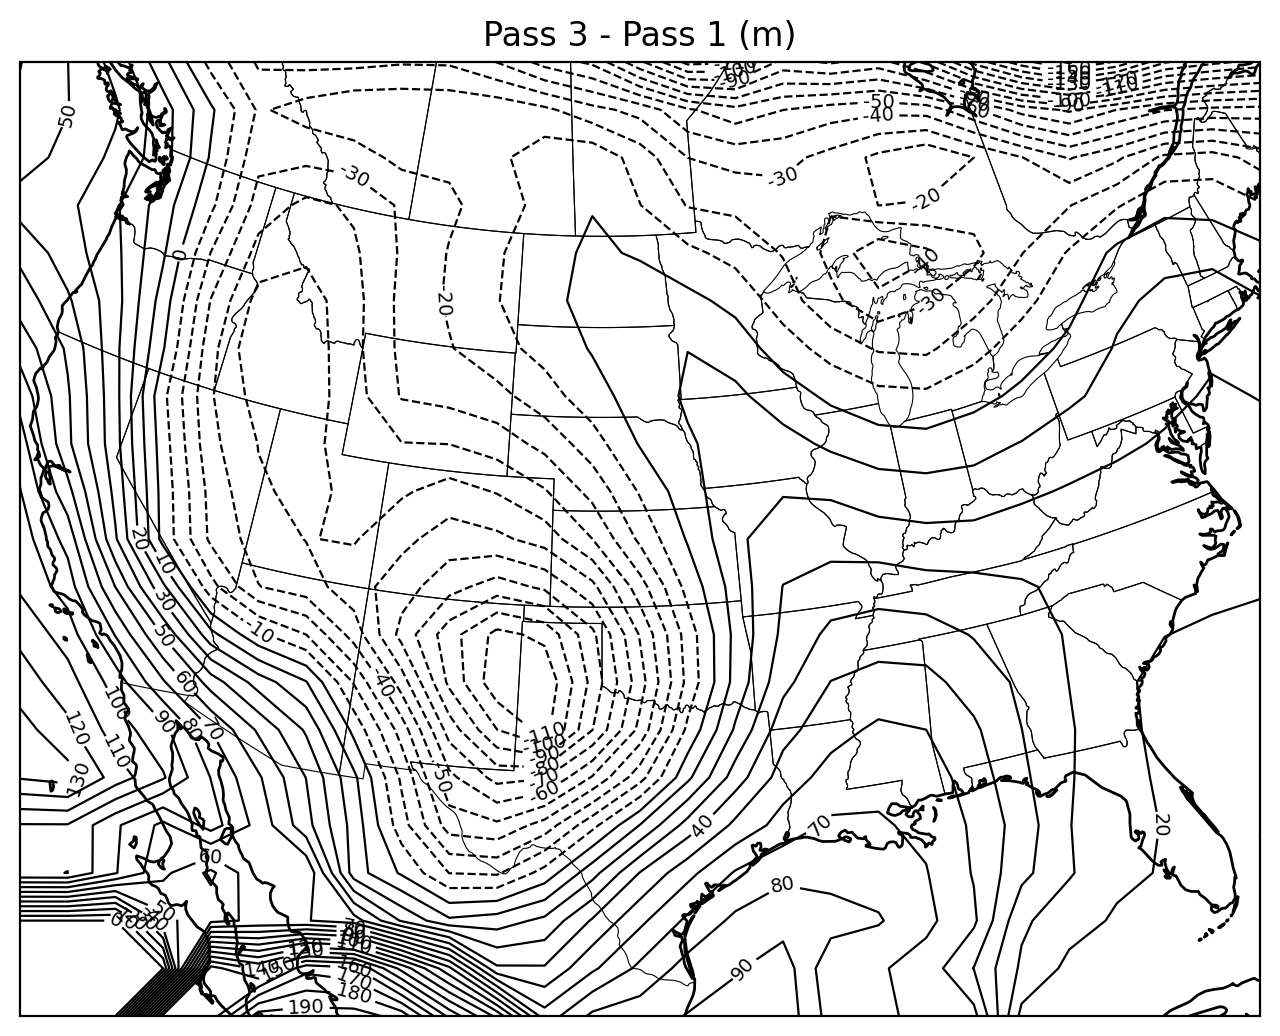

In [160]:
### Plot Analysis Differences ###

# pass 2 - pass 1
lim21 = 10 * np.ceil(np.nanmax(np.abs(diff21)) / 10)
levels21 = np.arange(-lim21, lim21 + 1, 10)

fig = plt.figure(figsize=(8, 8), dpi=200)
ax4 = fig.add_subplot(111, projection=proj)
ax4.add_feature(cfeature.STATES, linewidth=0.4)
ax4.add_feature(cfeature.COASTLINE)
cs4 = ax4.contour(map_x, map_y, diff21, levels=levels21, colors='k', linewidths=0.8, transform=proj)
ax4.clabel(cs4, fmt='%d', fontsize=7)
ax4.set_extent([map_x.min(), map_x.max(), map_y.min(), map_y.max()], crs=proj)
ax4.set_title('Pass 2 - Pass 1')
#plt.savefig('diff21_map.png', dpi=300, bbox_inches='tight')
plt.show()

# pass 3 - pass 2
lim32 = 10 * np.ceil(np.nanmax(np.abs(diff32)) / 10)
levels32 = np.arange(-lim32, lim32 + 1, 10)

fig = plt.figure(figsize=(8, 8), dpi=200)
ax5 = fig.add_subplot(111, projection=proj)
ax5.add_feature(cfeature.STATES, linewidth=0.4)
ax5.add_feature(cfeature.COASTLINE)
cs5 = ax5.contour(map_x, map_y, diff32, levels=levels32, colors='k', linewidths=0.8, transform=proj)
ax5.clabel(cs5, fmt='%d', fontsize=7)
ax5.set_extent([map_x.min(), map_x.max(), map_y.min(), map_y.max()], crs=proj)
ax5.set_title('Pass 3 - Pass 2')
#plt.savefig('diff32_map.png', dpi=300, bbox_inches='tight')
plt.show()

# pass 3 - pass 1
lim31 = 10 * np.ceil(np.nanmax(np.abs(diff31)) / 10)
levels31 = np.arange(-lim31, lim31 + 1, 10)

fig = plt.figure(figsize=(8, 8), dpi=200)
ax6 = fig.add_subplot(111, projection=proj)
ax6.add_feature(cfeature.STATES, linewidth=0.4)
ax6.add_feature(cfeature.COASTLINE)
cs6 = ax6.contour(map_x, map_y, diff31, levels=levels31, colors='k', linewidths=0.8, transform=proj)
ax6.clabel(cs6, fmt='%d', fontsize=7)
ax6.set_extent([map_x.min(), map_x.max(), map_y.min(), map_y.max()], crs=proj)
ax6.set_title('Pass 3 - Pass 1 (m)')
#plt.savefig('diff31_map.png', dpi=300, bbox_inches='tight')
plt.show()

In [145]:
### Store the analyses in text files ###
analyses = [pass1, pass2, pass3]
names  = ["pass1_analysis", "pass2_analysis", "pass3_analysis"]

for name, field in zip(names,analyses):
    out = np.column_stack([np.repeat(np.arange(NX), NY), np.tile(np.arange(NY), NX), 
                           x_cm.ravel(), y_cm.ravel(), map_x.ravel(), map_y.ravel(), field.ravel()])
    np.savetxt(f"{name}.txt", out,header="i j x_cm y_cm lat lon value",fmt=["%d", "%d", "%.4f", "%.4f", "%.4f", "%.4f", "%.1f"])

In [143]:
### Store the difference fields in text files ###
for tag, D in [("2-1", diff21), ("3-1", diff31), ("3-2", diff32)]:
    np.savetxt(f"diff_{tag}.txt", D, fmt="%.1f", delimiter=",")

In [147]:
### Store RMS values in text file ###
rms = [rmse1,rmse2,rmse3]

with open("rms.txt", "w") as f:
    for tag, r in zip(["pass1", "pass2", "pass3"], rms):
        f.write(f"{tag}, {r:.2f}\n")

In [ ]:
### In a separte text file (or below), answer the following questions ###
'''
1 - Describe the general features that you see in your contoured analyses.

    All of the passes paint a similar picture showing a trough in over the western half of the United States, centered over the Rockies,
    and a ridge in the east centered over the great lakes and into the Ohio Valley. The trough looks deeper with each pass, as the 540 dam contour
    is restrained to Canada in pass 1, but extends into Montana in pass 2, and reaches down into southern Idaho in pass 3. As the passes progress,
    the apex of the ridge seems to flatten out and become more zonal, and the gradient in isoheights becomes larger, especially over Texas.
    The difference plots show larger differences in successive passes near where we would expect the extremes in geopotential height (over the TX/NM 
    border and over the Gulf of Mexico.

2 - Describe the differences that you see in your contoured analyses.  
    Does one analysis seem to be smoother than the other?  If so, what would cause this?

    The contours become less smooth with each pass with pass 1 being the smoothest and not representing extremes well, leaving pass 3 the least smooth 
    and the overall analysis becoming more noisy. This is especially noticable at the nadir of the trough. It's axis isn't very tilted, 
    nor are the contours rough in pass 1, but it protrudes down into New Mexico and Texas in pass 2 and even more in pass 3, and the contours have
    more kinks in them as the passes increase. There's something weird going on with the contours over Baja California that becomes visible in pass 2
    and is very evident in pass 3, but this is a product of not having observations within this region, so what's going on here isn't a real feature. 
    With each pass, the radius of influence decreases and the analysis points are influenced by fewer and fewer obs, so more smaller scale noise
    is included in the analysis, making any extremes more exaggerated than in previous passes.
    

3 - What happens as you increase the number of successive correction passes?  Is this 
    desirable?  Why or why not?

    As you increase the number of passes and the radius of influence gets smaller, the analysis better fits the observations and decreases the RMS 
    difference with each pass. Each pass lets through more smaller scale data than the last, which lets you see smaller scale features. 
    This could be a good thing, and would be if observations were perfect, but they're not. The closer and closer you get to fitting the obs, 
    the more you fit obs error as well. Many passes sounds good in theory, but you'd end up with small bulleyes and kinks around stations that 
    don't really represent real atmospheric features. There's a point where analysis fits as well as obs error will allow, but further passes begin to 
    fit noise rather than reality.

'''